# 과제 2 — ACT 정책 학습 및 실로봇 평가

**과제 내용**: 과제 1에서 수집한 데이터셋으로 ACT 정책을 학습하고, 실제 로봇에서 10회 평가해 성공률을 측정한 뒤, 학습된 정책을 Huggingface Hub에 업로드한다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1과 같은 저장소, assignments 폴더)에 `assignment_2.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`를 추가할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [1]:
# 제출 정보
STUDENT_ID = "2021136016"
NAME = "김동찬"
HF_USER = "dongchan01"

TASK = "Grab the black cube"

TRAIN_DATASET = f"{HF_USER}/pick-cube_20261008_100853"
POLICY_REPO   = f"{HF_USER}/act_pick_cube"
EVAL_DATASET  = f"{HF_USER}/eval_act_pick_cube"
WANDB_URL     = "https://wandb.ai/doungchan-korea-university-of-technology-and-education/lerobot/runs/1itj37lp"

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("정책 모델     :", f"https://huggingface.co/{POLICY_REPO}")
print("평가 데이터셋 :", f"https://huggingface.co/datasets/{EVAL_DATASET}")
print("wandb         :", WANDB_URL or "(미사용)")


학번/이름     : 2021136016 김동찬
태스크        : Grab the black cube
학습 데이터셋 : https://huggingface.co/datasets/dongchan01/pick-cube_20261008_100853
정책 모델     : https://huggingface.co/dongchan01/act_pick_cube
평가 데이터셋 : https://huggingface.co/datasets/dongchan01/eval_act_pick_cube
wandb         : https://wandb.ai/doungchan-korea-university-of-technology-and-education/lerobot/runs/1itj37lp


→ 과제 1의 데이터셋을 반드시 사용하지 않아도 됨.

In [2]:
# Hub 접근 확인 — 세 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset"), (POLICY_REPO, "model"), (EVAL_DATASET, "dataset")]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

OK   [dataset] dongchan01/pick-cube_20261008_100853  (파일 9개)


OK   [model  ] dongchan01/act_pick_cube  (파일 20개)


OK   [dataset] dongchan01/eval_act_pick_cube  (파일 8개)


## 1. 학습 설정

### 1-1. 실행한 학습 명령어

과제 1에서 수집한 50개 에피소드 데이터셋으로 ACT 정책을 100,000 step 학습했다.

```bash
lerobot-train \
  --dataset.repo_id=dongchan01/pick-cube_20261008_100853 \
  --policy.type=act \
  --policy.device=cuda \
  --policy.repo_id=dongchan01/act_pick_cube \
  --output_dir=outputs/train/act_pick_cube \
  --job_name=act_pick_cube \
  --batch_size=8 \
  --steps=100000 \
  --wandb.enable=true
```

Backend.AI 세션이 교체된 뒤 Hugging Face에 백업한 80,000 step 체크포인트를 내려받아 다음 명령으로 재개했다.

```bash
lerobot-train \
  --config_path=/home/work/outputs/train/act_pick_cube/checkpoints/last/pretrained_model/train_config.json \
  --resume=true
```

### 1-2. 학습 환경

- GPU: NVIDIA H200 자원 분할 환경(할당 GPU 메모리 약 21 GB)
- 학습 step 수: 100,000
- batch size: 8
- 소요 시간: 6,472초(약 1시간 48분, W&B runtime 기준)
- 기본값에서 변경한 ACT 모델 하이퍼파라미터: 없음. 과제에서 지정한 `batch_size=8`, `steps=100000`을 명시했다.
- LeRobot: 0.6.0, 정책 장치: CUDA


In [3]:
# 업로드된 정책의 설정 확인
def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{filename} 불러오기 실패: {type(e).__name__}")
        return None

policy_cfg = load_json(POLICY_REPO, "config.json")
if policy_cfg:
    print("== 정책 설정 (config.json) ==")
    for k in ["type", "chunk_size", "n_action_steps", "n_obs_steps",
              "vision_backbone", "dim_model", "use_vae", "kl_weight", "optimizer_lr"]:
        if k in policy_cfg:
            print(f"{k:16}: {policy_cfg[k]}")

train_cfg = load_json(POLICY_REPO, "train_config.json")
if train_cfg:
    print("\n== 학습 설정 (train_config.json) ==")
    print("dataset   :", train_cfg.get("dataset", {}).get("repo_id"))
    for k in ["steps", "batch_size", "seed"]:
        if k in train_cfg:
            print(f"{k:10}: {train_cfg[k]}")

== 정책 설정 (config.json) ==
type            : act
chunk_size      : 100
n_action_steps  : 100
n_obs_steps     : 1
vision_backbone : resnet18
dim_model       : 512
use_vae         : True
kl_weight       : 10.0
optimizer_lr    : 1e-05



== 학습 설정 (train_config.json) ==
dataset   : dongchan01/pick-cube_20261008_100853
steps     : 100000
batch_size: 8
seed      : 1000


### 1-3. 학습 곡선

W&B 완료 run에서 `train/loss`를 내려받아 그린 곡선이다. 최종 100,000 step의 loss는 약 0.049였다.

[W&B 학습 기록](https://wandb.ai/doungchan-korea-university-of-technology-and-education/lerobot/runs/1itj37lp)

![loss curve](images/loss_curve.png)


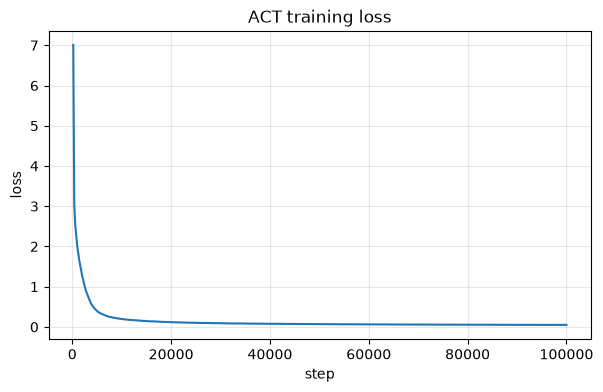

기록 수: 500, 최종 step: 100000, 최종 loss: 0.0490


In [4]:
# W&B에서 내려받은 학습 loss를 직접 그려 확인
import os
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "images/loss.csv"
df = pd.read_csv(CSV_PATH)
plt.figure(figsize=(7, 4))
plt.plot(df["step"], df["loss"], color="tab:blue")
plt.xlabel("step")
plt.ylabel("loss")
plt.title("ACT training loss")
plt.grid(alpha=0.3)
plt.show()
print(f"기록 수: {len(df)}, 최종 step: {int(df['step'].iloc[-1])}, 최종 loss: {df['loss'].iloc[-1]:.4f}")


## 2. 실로봇 평가 (10회)

### 2-1. 평가 명령어

LeRobot 0.6.0에서는 정책 기반 실로봇 실행이 `lerobot-record`에서 `lerobot-rollout`으로 분리되어 있어 episodic rollout을 사용했다. 또한 rollout 데이터셋 이름은 `rollout_`으로 시작해야 하므로 로컬에 먼저 기록한 뒤 과제용 `eval_` 저장소에 수동 업로드했다.

```bash
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=dongchan01/act_pick_cube \
  --policy.device=cuda \
  --robot.type=so101_follower \
  --robot.port=/dev/so101_follower \
  --robot.id=follower1 \
  --robot.cameras="{ overhead: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, wrist: {type: opencv, index_or_path: 2, width: 640, height: 480, fps: 30}}" \
  --dataset.repo_id=dongchan01/rollout_eval_act_pick_cube \
  --dataset.root=/home/koreatech/eval_act_pick_cube_dataset \
  --dataset.single_task="Grab the black cube" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15 \
  --dataset.push_to_hub=false \
  --display_data=true
```

```bash
hf upload dongchan01/eval_act_pick_cube \
  /home/koreatech/eval_act_pick_cube_dataset \
  --repo-type dataset
```


In [5]:
# 평가 데이터셋 메타데이터 확인 — 에피소드 수가 10이어야 한다
info = load_json(EVAL_DATASET, "meta/info.json", repo_type="dataset")
if info:
    n_ep = info.get("total_episodes")
    print("평가 에피소드 수:", n_ep)
    print("총 프레임 수    :", info.get("total_frames"))
    print("fps             :", info.get("fps"))
    print("카메라          :", [k for k in info.get("features", {}) if k.startswith("observation.images")])
    print("\n에피소드 수 확인:", "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")

info.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

평가 에피소드 수: 10
총 프레임 수    : 8957
fps             : 30
카메라          : ['observation.images.overhead', 'observation.images.wrist']

에피소드 수 확인: 통과


### 2-2. 회차별 결과

아래 결과는 10회 실로봇 평가를 직접 관찰해 기록한 것이다. 에피소드 번호는 데이터셋의 0~9 인덱스를 사용했다.


In [6]:
results = [
    {"episode": 0, "success": False, "note": "큐브 오른쪽에서 여러 차례 헛손질했고 마지막 시도에서도 잡지 못함"},
    {"episode": 1, "success": True,  "note": "두 번째 시도에서 큐브를 잡는 데 성공함"},
    {"episode": 2, "success": False, "note": "한 번에 큐브를 잡았으나 가져오는 도중 놓침"},
    {"episode": 3, "success": True,  "note": "오른쪽에서 약간 헛손질했지만 세 번째 시도에서 잡는 데 성공함"},
    {"episode": 4, "success": False, "note": "집게가 큐브를 작업 범위 밖으로 밀어내어 잡지 못함"},
    {"episode": 5, "success": False, "note": "큐브의 완전히 오른쪽에서 헛손질함"},
    {"episode": 6, "success": False, "note": "큐브 바로 오른쪽에서 헛손질함"},
    {"episode": 7, "success": False, "note": "큐브 바로 오른쪽에서 헛손질함"},
    {"episode": 8, "success": False, "note": "집게가 큐브를 넘어뜨린 뒤 오른쪽에서 헛손질함"},
    {"episode": 9, "success": False, "note": "큐브 오른쪽에서 헛손질함"},
]

res_df = pd.DataFrame(results)
n_success = int(res_df["success"].sum())
print(f"성공률: {n_success}/{len(res_df)} = {n_success/len(res_df)*100:.0f}%")
res_df


성공률: 2/10 = 20%


,episode,success,note
0,0,False,큐브 오른쪽에서 여러 차례 헛손질했고 마지막 시도에서도 잡지 못함
1,1,True,두 번째 시도에서 큐브를 잡는 데 성공함
2,2,False,한 번에 큐브를 잡았으나 가져오는 도중 놓침
3,3,True,오른쪽에서 약간 헛손질했지만 세 번째 시도에서 잡는 데 성공함
4,4,False,집게가 큐브를 작업 범위 밖으로 밀어내어 잡지 못함
5,5,False,큐브의 완전히 오른쪽에서 헛손질함
6,6,False,큐브 바로 오른쪽에서 헛손질함
7,7,False,큐브 바로 오른쪽에서 헛손질함
8,8,False,집게가 큐브를 넘어뜨린 뒤 오른쪽에서 헛손질함
9,9,False,큐브 오른쪽에서 헛손질함


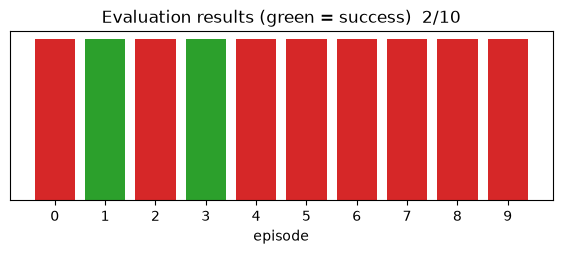

In [7]:
# 회차별 결과 시각화
colors = ["tab:green" if s else "tab:red" for s in res_df["success"]]
plt.figure(figsize=(7, 2.2))
plt.bar(res_df["episode"].astype(str), [1]*len(res_df), color=colors)
plt.yticks([]); plt.xlabel("episode")
plt.title(f"Evaluation results (green = success)  {n_success}/{len(res_df)}")
plt.show()

### 2-3. 평가 영상

[LeRobot 데이터셋 웹 뷰어](https://huggingface.co/spaces/lerobot/visualize_dataset)에 `dongchan01/eval_act_pick_cube`를 입력해 10개 에피소드가 재생되는 것을 확인했다. 아래 GIF는 wrist 카메라 영상에서 추출한 대표 성공 회차(episode 1)와 실패 회차(episode 0)이다.

**대표 성공 장면 — episode 1**

![success](images/success.gif)

**대표 실패 장면 — episode 0**

![failure](images/failure.gif)


## 3. 고찰

### 3-1. 실패 원인 분석

10회 중 2회 성공해 성공률은 20%였고, 실패 8회 중 6회에서 집게가 큐브보다 오른쪽으로 이동하는 공통 패턴이 나타났다. 한 회차에서는 큐브를 잡은 뒤 이동 중 놓쳤고, 다른 회차에서는 집게가 큐브를 작업 범위 밖으로 밀어냈다. 이는 정책이 카메라 영상의 물체 위치 변화에 충분히 일반화하지 못하고, 첫 접근에 실패한 뒤 위치를 다시 보정하는 능력도 부족했기 때문이라고 판단한다.

### 3-2. 데이터와 성능의 관계

과제 1의 시연은 동일한 카메라 구도와 비교적 제한된 큐브 위치에서 수집되어 동작 자체는 학습할 수 있었지만 위치 다양성이 부족했다. 평가에서는 작은 카메라 각도나 큐브 위치 차이가 오른쪽 방향의 체계적인 오차로 이어진 것으로 보인다. 또한 잡은 뒤 이동 중 떨어뜨리는 상황과 실패 후 재접근하는 상황의 시연이 부족해 정책이 예외 상황에서 회복하지 못했다.

### 3-3. 개선 아이디어

성공률을 높이려면 카메라와 로봇 시작 자세를 고정한 상태에서 큐브의 좌우·전후 위치를 균형 있게 바꾸어 추가 시연을 수집해야 한다. 특히 오른쪽으로 빗나가는 경향을 줄이기 위해 큐브가 여러 위치에 있을 때 정확히 중앙으로 접근하는 시연과, 놓치거나 밀어낸 뒤 재접근하는 복구 시연을 포함하겠다. 데이터 품질을 확인한 뒤 추가 데이터로 ACT 정책을 재학습하고 같은 조건의 10회 평가로 개선 여부를 비교하겠다.


## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [8]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

check_items = {
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "정책 모델 업로드됨 (config.json)": file_ok(POLICY_REPO, "config.json", "model"),
    "정책 가중치 업로드됨 (model.safetensors)": file_ok(POLICY_REPO, "model.safetensors", "model"),
    "평가 데이터셋 에피소드 10개": bool(info) and info.get("total_episodes") == 10,
    "회차별 결과 10개 입력": len(results) == 10,
    "실패 회차에 원인 기재": all(r["note"].strip() for r in results if not r["success"]),
}
for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] 학습 데이터셋 접근 가능 (public)
[통과] 정책 모델 업로드됨 (config.json)
[통과] 정책 가중치 업로드됨 (model.safetensors)
[통과] 평가 데이터셋 에피소드 10개
[통과] 회차별 결과 10개 입력
[통과] 실패 회차에 원인 기재

모두 통과
